# Мгновенная частота и локальные осцилляторы: EMD с равномерным ядром

**Выполненный Jupyter Notebook на Python.** Разложение IF, передискретизация по фазе RIF,
аналитический сигнал, квадратура и интегральная форма. Все данные синтетические,
с известными компонентами для независимого измерения ошибок.

Основание: статья **«Выявление мгновенных частот и локальных осцилляторов с помощью
разложения на эмпирические моды со сглаживающим ядром»**, версия от 8 октября 2026 года.
Номера формул далее относятся к этой статье.

| Раздел | Что проверяем |
|:--|:--|
| 1–2 | Реализация и соответствие формул кодовым функциям |
| 3 | Неустойчивость одинарного среднего; длины 3 и 5 |
| 4 | Сумма по мере Дирака, FFT, интегральные матрицы, комплексное ядро |
| 5 | Точное воспроизведение двухтонального примера статьи |
| 6 | Автоматическая оценка двух масштабов по данным |
| 7 | Чирп-сигнал статьи: фиксированная и адаптивная фильтрация |
| 8 | AM-сигнал, квадратура и шум |
| 9 | Нули амплитуды и частота аналитического сигнала смеси |
| 10 | Синтез, частотная плотность и проекция по аналогии с ДПФ |
| 11 | Итог проверок и работа с собственным сигналом |

**Два разных критерия.** Тождество $x=\sum_j c_j+r_J$ проверяет сохранение сигнала.
Сравнение $c_j$ и $f_j$ с известными истинными компонентами проверяет их выявление.
Одно не заменяет другого.

Это IF/RIF, основанные на идеях EMD; сплайновые огибающие классического EMD не используются.

## 1. Запуск и соглашения

Блокнот самодостаточен: весь алгоритм находится в его ячейках; соседний модуль
*kernel_emd.py* не нужен для запуска. Выберите **Kernel → Restart Kernel and Run All Cells**.

Установка в отдельном окружении:
```bash
python -m pip install -r requirements.txt
jupyter lab emd_kernel_demo_ru.ipynb
```

Для зафиксированных зависимостей нужен Python ≥ 3.11. NumPy 2.3.5, SciPy 1.17.0,
Matplotlib 3.10.8, pandas 2.2.3. Версии текущего запуска выводятся ниже.
Блокнот не устанавливает пакеты и не загружает данные из интернета.

Частота измеряется в Гц, время — в секундах. Параметр *length* относится к базовому
вектору длины $L$. Двойной фильтр имеет эффективную длину $2L-1$.

In [1]:
import sys
import numpy as np
import scipy
import matplotlib
import matplotlib.pyplot as plt
import pandas as pd

try:
    from IPython.display import display
except ImportError:
    def display(obj):
        print(obj.to_string() if hasattr(obj, "to_string") else obj)

plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "figure.dpi": 110,
})
BLUE, ORANGE, TEAL, GREY = "#245a9b", "#b96533", "#13857e", "#7d8792"
checks = []
summary_metrics = {}
SEED = 20261009

def check(name, condition, detail=""):
    passed = bool(condition)
    checks.append({"Проверка": name, "Пройдена": passed, "Комментарий": detail})
    assert passed, name + ": " + detail

def must_raise(name, function):
    try:
        function()
    except ValueError:
        check(name, True)
    else:
        check(name, False, "Ожидалось ValueError")

display(pd.DataFrame({
    "Компонент": ["Python", "NumPy", "SciPy", "Matplotlib", "pandas", "Seed"],
    "Версия / значение": [sys.version.split()[0], np.__version__, scipy.__version__,
                         matplotlib.__version__, pd.__version__, str(SEED)],
}))

    Компонент Версия / значение
0      Python           3.12.14
1       NumPy             2.3.5
2       SciPy            1.17.0
3  Matplotlib            3.10.8
4      pandas             2.2.3
5        Seed          20261009


## 2. Реализация метода

Базовое ядро:
$$b_L[q]=1/L,\qquad h_{m+1}=h_m-M_Lh_m.$$

Основной вариант использует автокорреляцию $w_L=b_L*b_L^\vee$.
При $L=3$ эффективные веса равны $[1,2,3,2,1]/9$.
Его периодическая характеристика $W_L=|B_L|^2\in[0,1]$,
а множитель просеивания равен $(1-W_L)^m$ — формулы (5), (13), (15).

| Функция | Назначение |
|:--|:--|
| *sift_fixed*, *decompose_fixed* | Фиксированные длины и конечное число шагов |
| *decompose_auto* | Выбор длины по экстремумам текущего остатка |
| *sift_variable* | Экспериментальный замороженный профиль $L[n]$ |
| *phase_resampled_sift* | Усреднение в фазовой координате |
| *hilbert_guided_extract* | Пилот по данным → оценка фазы → уточнение RIF |
| *analytic_features*, *quadrature_features* | Частота и осциллятор |
| *decomposition_operators* | Условные дискретные интегральные ядра |
| *synthesize_from_intervals*, *frequency_density* | Синтез и представление с фазой |
| *oscillator_projection* | Коэффициенты с поправкой на матрицу Грама |

FFT-форма используется только при *boundary="wrap"* и фиксированном числе шагов.
При *boundary="reflect"* применяется прямая свёртка с зеркальным продолжением.
*mean_tol* даёт необязательную остановку по $\|Mh\|/\|h\|$, а *iterations* — её предел.
Это критерий среднего по ядру, а не доказательство классических условий IMF.

In [2]:
"""Итеративная фильтрация равномерным ядром и анализ мгновенной частоты.

Это kernel-based IF/RIF из статьи, а не сплайновая реализация классического EMD.
NumPy и SciPy; длина относится к элементарному вектору, до автокорреляции.
"""
from __future__ import annotations

from dataclasses import dataclass
from numbers import Integral
import warnings

import numpy as np
from scipy import ndimage, signal
from scipy.integrate import cumulative_trapezoid


def _integer(value, name, minimum=1):
    if isinstance(value, (bool, np.bool_)) or not isinstance(value, Integral):
        raise ValueError(f"{name}: требуется целое число")
    if value < minimum:
        raise ValueError(f"{name} должно быть >= {minimum}")
    return int(value)


def _real_signal(x):
    if np.iscomplexobj(x):
        raise ValueError("Входной сигнал должен быть вещественным")
    x = np.asarray(x, dtype=np.float64)
    if x.ndim != 1 or len(x) < 3 or not np.all(np.isfinite(x)):
        raise ValueError("Нужен конечный одномерный сигнал минимум из 3 отсчётов")
    return x


def _sample_rate(fs):
    if not np.isscalar(fs) or not np.isfinite(fs) or fs <= 0:
        raise ValueError("fs должна быть конечной положительной частотой в Гц")
    return float(fs)


@dataclass
class SiftResult:
    mode: np.ndarray
    iterations: int
    length: int | np.ndarray
    reason: str
    mean_ratio: float


@dataclass
class Decomposition:
    modes: np.ndarray
    residual: np.ndarray
    lengths: list[int]
    iterations: list[int]
    reason: str

    def reconstruct(self):
        return self.residual + self.modes.sum(axis=0)


@dataclass
class AnalyticFeatures:
    z: np.ndarray
    amplitude: np.ndarray
    phase: np.ndarray
    frequency: np.ndarray
    oscillator: np.ndarray
    valid: np.ndarray

### Центрированный фильтр и фиксированный масштаб: формулы (2), (5), (13), (15).

In [3]:
def averaging_kernel(length, *, double=True):
    """Возвращает веса и целочисленные смещения центрированного фильтра.

    double=True: w=b*reverse(b), длина 2L-1, возможно любое целое L.
    double=False: сам b с весами 1/L; для центрирования нужна нечётная L.
    """
    length = _integer(length, "length")
    if not double and length % 2 == 0:
        raise ValueError("Для одинарного центрированного фильтра нужна нечётная L")
    b = np.ones(length, dtype=np.float64) / length
    weights = np.convolve(b, b[::-1]) if double else b
    radius = len(weights) // 2
    return weights, np.arange(-radius, radius + 1)


def periodic_response(n, length, *, double=True):
    """ДПФ именно центрированного эффективного фильтра, без фазового сдвига."""
    n = _integer(n, "n", 3)
    weights, offsets = averaging_kernel(length, double=double)
    impulse = np.zeros(n)
    np.add.at(impulse, offsets % n, weights)
    response = np.fft.rfft(impulse).real
    return np.clip(response, 0.0, 1.0) if double else response


def moving_average(x, length, *, double=True, boundary="reflect"):
    """Зеркальное (half-sample reflect) или циклическое продолжение."""
    x = _real_signal(x)
    if boundary not in {"reflect", "wrap"}:
        raise ValueError("boundary: 'reflect' или 'wrap'")
    weights, _ = averaging_kernel(length, double=double)
    return ndimage.convolve1d(x, weights, mode=boundary, origin=0)


def sift_fixed(x, length, *, iterations=8, double=True, boundary="reflect",
               backend="auto", mean_tol=None, min_iterations=1):
    """h <- h-Mh; фиксированный фильтр внутри одного просеивания.

    iterations — конечное число шагов / верхний предел при mean_tol.
    mean_tol: ||Mh||/||h||; это критерий среднего по ядру, не гарантия IMF.
    FFT допустима только для wrap и фиксированного числа шагов.
    """
    x = _real_signal(x)
    iterations = _integer(iterations, "iterations", 0)
    min_iterations = _integer(min_iterations, "min_iterations", 0)
    length = _integer(length, "length")
    if boundary not in {"reflect", "wrap"} or backend not in {"auto", "fft", "direct"}:
        raise ValueError("Неверные boundary или backend")
    if mean_tol is not None and (not np.isfinite(mean_tol) or mean_tol <= 0):
        raise ValueError("mean_tol должна быть положительной")
    averaging_kernel(length, double=double)
    if backend == "fft" and (boundary != "wrap" or mean_tol is not None):
        raise ValueError("FFT требует wrap и mean_tol=None")
    use_fft = backend == "fft" or (backend == "auto" and boundary == "wrap" and mean_tol is None)
    if use_fft:
        response = periodic_response(len(x), length, double=double)
        h = np.fft.irfft(np.fft.rfft(x) * (1.0 - response)**iterations, n=len(x))
        count, reason = iterations, "fixed_iterations"
    else:
        h, count, reason = x.copy(), 0, "fixed_iterations"
        for k in range(iterations):
            mean = moving_average(h, length, double=double, boundary=boundary)
            ratio = np.linalg.norm(mean) / max(np.linalg.norm(h), np.finfo(float).tiny)
            if mean_tol is not None and k >= min_iterations and ratio <= mean_tol:
                reason = "mean_tolerance"
                break
            h = h - mean
            count += 1
            if not np.all(np.isfinite(h)):
                raise FloatingPointError("Просеивание стало нечисловым")
    mean = moving_average(h, length, double=double, boundary=boundary)
    ratio = float(np.linalg.norm(mean) / max(np.linalg.norm(h), np.finfo(float).tiny))
    return SiftResult(h, count, length, reason, ratio)


def decompose_fixed(x, lengths, *, iterations=8, boundary="wrap", backend="auto"):
    """Последовательное извлечение: c_j=P_j r_(j-1); остаток сохраняется."""
    x = _real_signal(x)
    lengths = list(lengths)
    counts = [iterations] * len(lengths) if isinstance(iterations, Integral) else list(iterations)
    if len(counts) != len(lengths):
        raise ValueError("Нужен один iterations на каждую длину")
    modes, used, residual = [], [], x.copy()
    for length, count in zip(lengths, counts):
        result = sift_fixed(residual, length, iterations=count,
                            boundary=boundary, backend=backend, double=True)
        modes.append(result.mode)
        used.append(result.iterations)
        residual = residual - result.mode
    modes = np.stack(modes) if modes else np.empty((0, len(x)))
    return Decomposition(modes, residual, [int(v) for v in lengths], used, "given_lengths")


def estimate_length_extrema(x):
    """Начальная эвристика: медиана полных периодов между однотипными экстремумами.

    Полный период уменьшает ошибку округления двух отдельных полупериодов.
    Ненадёжна при дополнительных экстремумах от шума и смешении компонент.
    """
    x = _real_signal(x)
    peaks = signal.find_peaks(x)[0]
    troughs = signal.find_peaks(-x)[0]
    periods = np.r_[np.diff(peaks), np.diff(troughs)]
    if len(periods) < 2:
        raise ValueError("Недостаточно экстремумов для оценки периода")
    return int(np.clip(np.rint(np.median(periods)), 3, len(x)))


def decompose_auto(x, fs, *, max_modes=6, iterations=8, boundary="reflect",
                   residual_tol=1e-8, mode_tol=1e-8, mean_tol=None):
    """Выбор L по текущему остатку; это эвристика без универсальной гарантии."""
    x, fs = _real_signal(x), _sample_rate(fs)
    max_modes = _integer(max_modes, "max_modes", 0)
    if residual_tol < 0 or mode_tol < 0:
        raise ValueError("Допуски должны быть неотрицательными")
    initial_norm = np.linalg.norm(x)
    residual, modes, lengths, counts = x.copy(), [], [], []
    reason = "max_modes"
    if initial_norm == 0:
        reason = "zero_signal"
    else:
        for _ in range(max_modes):
            if np.linalg.norm(residual) <= residual_tol * initial_norm:
                reason = "small_residual"
                break
            try:
                length = estimate_length_extrema(residual)
            except ValueError:
                reason = "insufficient_extrema"
                break
            result = sift_fixed(residual, length, iterations=iterations, boundary=boundary,
                                mean_tol=mean_tol, double=True)
            if np.linalg.norm(result.mode) <= mode_tol * initial_norm:
                reason = "small_mode"
                break
            modes.append(result.mode)
            lengths.append(length)
            counts.append(result.iterations)
            residual = residual - result.mode
    modes = np.stack(modes) if modes else np.empty((0, len(x)))
    return Decomposition(modes, residual, lengths, counts, reason)

### Переменная длина и фазовая передискретизация: формулы (10), (21)-(23).

In [4]:
def moving_average_variable(x, lengths, *, boundary="reflect"):
    """Точное локальное усреднение по нечётным L[n], через префиксные суммы."""
    x = _real_signal(x)
    lengths = np.asarray(lengths)
    if lengths.shape != x.shape or lengths.dtype.kind not in "iu":
        raise ValueError("lengths: целочисленный профиль длины сигнала")
    if np.any(lengths < 1) or np.any(lengths % 2 == 0) or np.any(lengths > len(x)):
        raise ValueError("Все L[n] должны быть положительными, нечётными и <= N")
    if boundary not in {"reflect", "wrap"}:
        raise ValueError("boundary: 'reflect' или 'wrap'")
    radii = (lengths - 1) // 2
    padding = int(radii.max())
    extended = np.pad(x, padding, mode="symmetric" if boundary == "reflect" else "wrap")
    prefix = np.r_[0.0, np.cumsum(extended)]
    centers = padding + np.arange(len(x))
    return (prefix[centers + radii + 1] - prefix[centers - radii]) / lengths


def sift_variable(x, lengths, *, iterations=8, boundary="reflect", growth_limit=5.0):
    """Экспериментальный ALIF с одинарным средним и замороженным L[n].

    Не переносит доказательство устойчивости фиксированной автокорреляции.
    Превышение роста вызывает исключение; это контроль, а не доказательство.
    """
    x = _real_signal(x)
    iterations = _integer(iterations, "iterations", 0)
    if not np.isfinite(growth_limit) or growth_limit <= 1:
        raise ValueError("growth_limit должен быть конечным и > 1")
    norm0, h = np.linalg.norm(x), x.copy()
    for _ in range(iterations):
        h = h - moving_average_variable(h, lengths, boundary=boundary)
        if not np.all(np.isfinite(h)) or np.linalg.norm(h) > growth_limit * max(norm0, np.finfo(float).tiny):
            raise RuntimeError("Переменный фильтр превысил допустимый рост")
    mean = moving_average_variable(h, lengths, boundary=boundary)
    ratio = np.linalg.norm(mean) / max(np.linalg.norm(h), np.finfo(float).tiny)
    return SiftResult(h, iterations, np.asarray(lengths).copy(), "fixed_iterations", float(ratio))


def phase_resampled_sift(x, fs, frequency_guide, *, iterations=8,
                          samples_per_cycle=64, oversample=4, max_grid_points=2_000_000):
    """Фильтрация в v=integral f_hat dt. Линейная интерполяция, без сплайнов.

    FIR-передискретизация во времени уменьшает интерполяционную ошибку.
    Элементарный вектор имеет равные веса на фазовой, а не временной сетке.
    Возвращает моду и диагностическую информацию о сетке.
    """
    x, fs = _real_signal(x), _sample_rate(fs)
    guide = np.asarray(frequency_guide, dtype=float)
    if guide.shape != x.shape or not np.all(np.isfinite(guide)):
        raise ValueError("frequency_guide должен быть конечным массивом длины N")
    if np.any(guide <= 0) or np.any(guide >= fs / 2):
        raise ValueError("Нужна положительная частота строго ниже Найквиста")
    samples_per_cycle = _integer(samples_per_cycle, "samples_per_cycle", 8)
    oversample = _integer(oversample, "oversample")
    max_grid_points = _integer(max_grid_points, "max_grid_points", 3)
    t = np.arange(len(x)) / fs
    if oversample > 1:
        x_up = signal.resample_poly(x, oversample, 1, padtype="reflect")[:oversample * (len(x) - 1) + 1]
        t_up = np.arange(len(x_up)) / (fs * oversample)
        f_up = np.interp(t_up, t, guide)
    else:
        x_up, t_up, f_up = x, t, guide
    v_up = cumulative_trapezoid(f_up, t_up, initial=0.0)
    if v_up[-1] < 3:
        raise ValueError("Нужно минимум три периода для фазового просеивания")
    grid_size = int(round(v_up[-1] * samples_per_cycle)) + 1
    if grid_size > max_grid_points:
        raise ValueError("Фазовая сетка слишком велика: уменьшите samples_per_cycle")
    v_grid = np.linspace(0, v_up[-1], grid_size)
    dv = v_grid[1] - v_grid[0]
    length = int(round(1.0 / dv))
    warped = np.interp(v_grid, v_up, x_up)
    result = sift_fixed(warped, length, iterations=iterations, boundary="reflect", double=True)
    v_at_t = np.interp(t, t_up, v_up)
    mode = np.interp(v_at_t, v_grid, result.mode)
    info = {"phase_grid_points": grid_size, "length_in_phase": length,
            "cycle_window": length * dv, "oversample": oversample,
            "mean_ratio": result.mean_ratio}
    return mode, info

### Аналитический сигнал, квадратура, осцилляторы: формулы (16)-(18), (24).

In [5]:
def analytic_features(x, fs, *, boundary="wrap", trim=0, amplitude_floor=1e-3,
                       smooth_window=None, derivative="phase"):
    """Частота в Гц; недостоверные отсчёты получают NaN, знак не исправляется.

    derivative='phase': центрированная разность развёрнутой фазы.
    derivative='spectral': Im(z'/z)/(2pi), только для периодических данных.
    smooth_window: нечётное окно Savitzky-Golay для производной фазы.
    """
    x, fs = _real_signal(x), _sample_rate(fs)
    trim = _integer(trim, "trim", 0)
    if 2 * trim >= len(x):
        raise ValueError("trim удаляет весь сигнал")
    if not 0 <= amplitude_floor < 1:
        raise ValueError("amplitude_floor должен лежать в [0,1)")
    if boundary not in {"wrap", "reflect"}:
        raise ValueError("boundary: 'reflect' или 'wrap'")
    if derivative not in {"phase", "spectral"}:
        raise ValueError("derivative: 'phase' или 'spectral'")
    if derivative == "spectral" and (boundary != "wrap" or smooth_window is not None):
        raise ValueError("Спектральная производная требует wrap без smooth_window")
    if boundary == "reflect":
        padding = min(len(x) - 1, max(3, int(fs)))
        z = signal.hilbert(np.pad(x, padding, mode="symmetric"))[padding:padding + len(x)]
    else:
        z = signal.hilbert(x)
    amplitude, phase = np.abs(z), np.unwrap(np.angle(z))
    width = 3
    if derivative == "spectral":
        dz = np.fft.ifft(2j * np.pi * np.fft.fftfreq(len(z), 1 / fs) * np.fft.fft(z))
        frequency = np.full(len(x), np.nan)
        np.divide(dz, z, out=dz, where=amplitude > 0)
        frequency[amplitude > 0] = dz[amplitude > 0].imag / (2 * np.pi)
    elif smooth_window is None:
        frequency = np.gradient(phase, 1 / fs, edge_order=2) / (2 * np.pi)
    else:
        width = _integer(smooth_window, "smooth_window", 5)
        if width % 2 == 0 or width > len(x):
            raise ValueError("smooth_window должна быть нечётной и <= N")
        frequency = signal.savgol_filter(phase, width, 3, deriv=1, delta=1 / fs) / (2 * np.pi)
    threshold = amplitude_floor * amplitude.max()
    valid = amplitude > threshold
    # Дефект фазы влияет и на соседние отсчёты дифференцирования.
    valid = ndimage.minimum_filter1d(valid.astype(np.uint8), size=width, mode="constant", cval=0).astype(bool)
    if trim:
        valid[:trim] = False
        valid[-trim:] = False
    frequency[~valid] = np.nan
    oscillator = np.full(len(x), np.nan + 1j * np.nan)
    np.divide(z, amplitude, out=oscillator, where=amplitude > 0)
    return AnalyticFeatures(z, amplitude, phase, frequency, oscillator, valid)


def quadrature_features(x, fs, envelope, *, trim=2):
    """Прямая квадратура при положительной известной/оценённой огибающей.

    Предполагаются монотонная возрастающая фаза и |x/envelope|<=1.
    Выход за диапазон не скрывается обрезанием больших ошибок.
    """
    x, fs = _real_signal(x), _sample_rate(fs)
    envelope = np.broadcast_to(np.asarray(envelope, dtype=float), x.shape)
    if not np.all(np.isfinite(envelope)) or np.any(envelope <= 0):
        raise ValueError("Огибающая должна быть конечной и строго положительной")
    v = x / envelope
    if np.any(np.abs(v) > 1 + 1e-10):
        raise ValueError("|x/envelope|>1: огибающая не согласована с сигналом")
    v = np.clip(v, -1, 1)
    sign = np.sign(np.gradient(v, 1 / fs, edge_order=2))
    nonzero = np.flatnonzero(sign)
    if not len(nonzero):
        raise ValueError("Не определено направление фазы постоянного сигнала")
    latest = np.maximum.accumulate(np.where(sign != 0, np.arange(len(v)), nonzero[0]))
    sign = sign[latest]
    q = -sign * np.sqrt(np.maximum(0, 1 - v**2))
    z = envelope * (v + 1j * q)
    phase = np.unwrap(np.angle(z))
    frequency = np.gradient(phase, 1 / fs, edge_order=2) / (2 * np.pi)
    trim = _integer(trim, "trim", 0)
    if 2 * trim >= len(x):
        raise ValueError("trim удаляет весь сигнал")
    valid = np.ones(len(x), dtype=bool)
    if trim:
        valid[:trim] = valid[-trim:] = False
    frequency[~valid] = np.nan
    return AnalyticFeatures(z, np.abs(z), phase, frequency, z / np.abs(z), valid)


def hilbert_guided_extract(x, fs, *, initial_length=None, iterations=8,
                            refinements=2, trim_seconds=1.0, smooth_window=51,
                            samples_per_cycle=64, oversample=4):
    """Начальный масштаб по экстремумам -> пилот -> фаза -> RIF.

    Истинные частоты не принимаются этой функцией. Профиль фиксируется
    внутри каждого просеивания; уточнение выполняется между его запусками.
    """
    x, fs = _real_signal(x), _sample_rate(fs)
    refinements = _integer(refinements, "refinements")
    if not np.isfinite(trim_seconds) or trim_seconds < 0:
        raise ValueError("trim_seconds должна быть неотрицательной")
    length = estimate_length_extrema(x) if initial_length is None else _integer(initial_length, "initial_length")
    pilot = sift_fixed(x, length, iterations=iterations, boundary="reflect").mode
    history, guide = [], None
    for _ in range(refinements):
        features = analytic_features(pilot, fs, boundary="reflect", trim=int(round(trim_seconds * fs)),
                                     amplitude_floor=0.05, smooth_window=smooth_window)
        valid = features.valid & (features.frequency > 0) & (features.frequency < fs / 2)
        interior = np.arange(len(x))
        trimmed = (interior >= int(round(trim_seconds * fs))) & (interior < len(x) - int(round(trim_seconds * fs)))
        if valid.sum() < 20 or valid[trimmed].mean() < 0.8:
            raise ValueError("Недостаточно надёжных положительных фазовых оценок")
        # Заполнение только для фильтрации; при оценке качества края исключаются.
        guide = np.interp(interior, interior[valid], features.frequency[valid])
        pilot, info = phase_resampled_sift(x, fs, guide, iterations=iterations,
                                           samples_per_cycle=samples_per_cycle, oversample=oversample)
        history.append(info | {"valid_fraction": float(valid.mean())})
    return pilot, guide, {"initial_length": length, "history": history}


def synthesize_from_intervals(amplitudes, phase0, interval_frequencies, residual, fs):
    """Дискретный вариант (24): f[n+1/2] — средняя частота на интервале.

    Интеграл = накопленная сумма f*dt; phase0 сохраняется, как у ДПФ.
    Для дифференцированной точечной частоты квадратура лишь приближённая.
    """
    fs, residual = _sample_rate(fs), _real_signal(residual)
    amplitudes = np.asarray(amplitudes, dtype=float)
    interval_frequencies = np.asarray(interval_frequencies, dtype=float)
    phase0 = np.asarray(phase0, dtype=float)
    if amplitudes.ndim != 2 or amplitudes.shape[1] != len(residual):
        raise ValueError("amplitudes: массив J x N")
    j, n = amplitudes.shape
    if phase0.shape != (j,) or interval_frequencies.shape != (j, n - 1):
        raise ValueError("Неверные размеры phase0 или interval_frequencies")
    if not all(np.all(np.isfinite(v)) for v in [amplitudes, phase0, interval_frequencies]):
        raise ValueError("Синтез требует конечных амплитуд и фаз на данном интервале")
    phase = phase0[:, None] + np.c_[np.zeros(j), 2 * np.pi * np.cumsum(interval_frequencies, axis=1) / fs]
    return residual + np.sum(amplitudes * np.cos(phase), axis=0)

### Условные интегральные операторы и локальная проекция: (8), (9), (25), (28).

In [6]:
def periodic_average_matrix(n, length, *, double=True):
    """Массы дискретного интегрального ядра. Только для небольших проверок."""
    n = _integer(n, "n", 3)
    if n > 512:
        raise ValueError("Плотная матрица предназначена только для N<=512")
    weights, offsets = averaging_kernel(length, double=double)
    matrix = np.zeros((n, n))
    rows = np.arange(n)
    for weight, offset in zip(weights, offsets):
        matrix[rows, (rows - offset) % n] += weight
    return matrix


def decomposition_operators(n, lengths, iterations=8):
    """K_j=P_j R_(j-1), R_j=(I-P_j) R_(j-1); параметры уже зафиксированы."""
    n = _integer(n, "n", 3)
    iterations = _integer(iterations, "iterations", 0)
    if n > 512:
        raise ValueError("Операторы предназначены только для N<=512")
    identity, remainder = np.eye(n), np.eye(n)
    kernels = []
    for length in lengths:
        mean = periodic_average_matrix(n, length)
        p = np.linalg.matrix_power(identity - mean, iterations)
        kernels.append(p @ remainder)
        remainder = (identity - p) @ remainder
    return kernels, remainder


def oscillator_projection(z, oscillators, *, window=None, ridge=0.0):
    """Взвешенная комплексная проекция с поправкой на матрицу Грама."""
    z = np.asarray(z, dtype=complex)
    u = np.asarray(oscillators, dtype=complex)
    if z.ndim != 1 or u.ndim != 2 or u.shape[1] != len(z) or not len(u):
        raise ValueError("z: N; oscillators: J x N")
    if not np.all(np.isfinite(z)) or not np.all(np.isfinite(u)):
        raise ValueError("Проекция требует конечных значений")
    weights = np.ones(len(z)) if window is None else np.asarray(window, dtype=float)
    if weights.shape != z.shape or not np.all(np.isfinite(weights)) or np.any(weights < 0) or weights.sum() <= 0:
        raise ValueError("Окно должно быть неотрицательным, длины N, с положительной суммой")
    if not np.isfinite(ridge) or ridge < 0:
        raise ValueError("ridge должна быть конечной и неотрицательной")
    weights = weights / weights.sum()
    gram = (u.conj() * weights) @ u.T
    b = (u.conj() * weights) @ z
    condition = float(np.linalg.cond(gram))
    if condition > 1e8 and ridge == 0:
        warnings.warn("Матрица Грама плохо обусловлена; коэффициенты ненадёжны", RuntimeWarning, stacklevel=2)
    coefficients = np.linalg.lstsq(gram + ridge * np.eye(len(u)), b, rcond=None)[0]
    return coefficients, gram, condition


def relative_error(actual, reference, mask=None):
    """Относительная L2-ошибка; при нулевой эталонной норме не определена."""
    actual, reference = np.asarray(actual), np.asarray(reference)
    if actual.shape != reference.shape:
        raise ValueError("Размеры actual и reference должны совпадать")
    if mask is not None:
        actual, reference = actual[mask], reference[mask]
    denominator = np.linalg.norm(reference)
    if denominator == 0:
        return float("nan")
    return float(np.linalg.norm(actual - reference) / denominator)


def frequency_density(features, frequency_grid, *, keep_phase=True):
    """Биннированный вариант (27) либо амплитудный спектр Гильберта.

    Плотность делится на df: интеграл по частоте = df*sum(density).
    Неопределённые и выходящие за сетку значения сохраняются в unassigned.
    Это необходимо для точного синтеза при keep_phase=True.
    """
    features = list(features)
    grid = np.asarray(frequency_grid, dtype=float)
    if not features or grid.ndim != 1 or len(grid) < 2 or not np.all(np.isfinite(grid)):
        raise ValueError("Нужны компоненты и конечная частотная сетка")
    df = grid[1] - grid[0]
    if df <= 0 or not np.allclose(np.diff(grid), df):
        raise ValueError("Сетка должна быть равномерной и возрастающей")
    n = len(features[0].z)
    dtype = complex if keep_phase else float
    density, unassigned = np.zeros((len(grid), n), dtype=dtype), np.zeros(n, dtype=dtype)
    for feature in features:
        if len(feature.z) != n:
            raise ValueError("Компоненты должны иметь одинаковую длину")
        weights = feature.z if keep_phase else feature.amplitude
        valid = feature.valid & np.isfinite(feature.frequency) & (feature.frequency >= grid[0]) & (feature.frequency <= grid[-1])
        samples = np.flatnonzero(valid)
        bins = np.rint((feature.frequency[valid] - grid[0]) / df).astype(int)
        np.add.at(density, (bins, samples), weights[valid] / df)
        unassigned[~valid] += weights[~valid]
    return density, unassigned

## 3. Пример 1: длины 3 и 5, усиление и устойчивость

Для одинарного среднего $B_3(\pi)=-1/3$, поэтому компонента на частоте
Найквиста усиливается в $(4/3)^{20}\approx315{,}34$ раза.
Положительные временные веса не означают положительной частотной характеристики.

Для двойного среднего множитель не превосходит единицу. Проверяем это на
периодическом случайном сигнале, а также проверяем выделение чистых тонов
в первом нуле фильтра для $L=3$ и $L=5$.

,Величина,Значение
0,Прогноз (4/3)^20,315.336855
1,Измеренное усиление,315.336855
2,Норма после двойного фильтра / до,0.602813


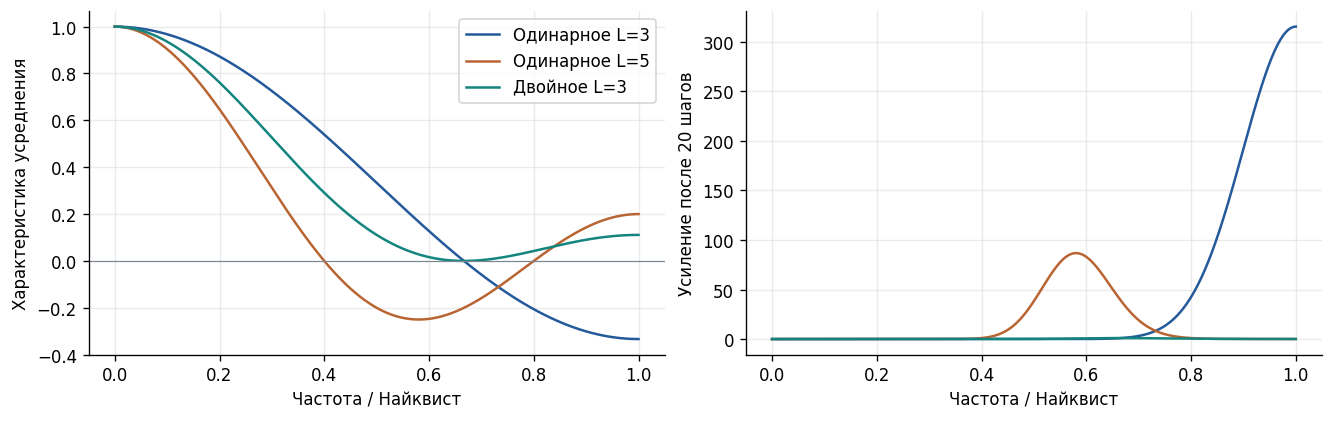

In [7]:
nyquist = (-1.0)**np.arange(512)
unstable = sift_fixed(nyquist, 3, iterations=20, double=False, boundary="wrap")
observed_gain = np.linalg.norm(unstable.mode) / np.linalg.norm(nyquist)
predicted_gain = (4/3)**20
check("L=3: коэффициент усиления совпадает с (4/3)^20",
      np.isclose(observed_gain, predicted_gain, rtol=1e-12))

theta = np.linspace(0, np.pi, 2001)
b3 = (1 + 2*np.cos(theta))/3
b5 = (1 + 2*np.cos(theta) + 2*np.cos(2*theta))/5
rng = np.random.default_rng(SEED)
random_x = rng.normal(size=512)
stable_x = sift_fixed(random_x, 5, iterations=20, boundary="wrap").mode
check("Двойное усреднение: периодическое просеивание не увеличивает L2-норму",
      np.linalg.norm(stable_x) <= np.linalg.norm(random_x)*(1 + 1e-12))

for length in [3, 5]:
    n = np.arange(600)
    pure_tone = np.cos(2*np.pi*n/length)
    result = sift_fixed(pure_tone, length, iterations=8, boundary="wrap")
    check(f"L={length}: тон в нуле фильтра сохраняется",
          relative_error(result.mode, pure_tone) < 1e-12)

summary_metrics["nyquist_gain_L3_m20"] = observed_gain
display(pd.DataFrame({
    "Величина": ["Прогноз (4/3)^20", "Измеренное усиление", "Норма после двойного фильтра / до"],
    "Значение": [predicted_gain, observed_gain, np.linalg.norm(stable_x)/np.linalg.norm(random_x)],
}))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4), constrained_layout=True)
for response, label, color in [
    (b3, "Одинарное L=3", BLUE), (b5, "Одинарное L=5", ORANGE),
    (b3**2, "Двойное L=3", TEAL),
]:
    ax[0].plot(theta/np.pi, response, label=label, color=color)
    ax[1].plot(theta/np.pi, (1-response)**20, color=color)
ax[0].axhline(0, color=GREY, lw=0.7)
ax[0].set(xlabel="Частота / Найквист", ylabel="Характеристика усреднения")
ax[0].legend()
ax[1].set(xlabel="Частота / Найквист", ylabel="Усиление после 20 шагов")
plt.show()

## 4. Проверка дискретной интегральной формы и FFT

Формула (3) — интеграл по дискретной мере Дирака; её массы уже содержат $1/L$.
В матричном варианте они не требуют дополнительного умножения на $\Delta t$.

Проверяем центрирование посредством независимой суммы с циклическими индексами,
включая чётную **базовую** длину 36 для автокорреляционного фильтра.
Для небольшого $N$ строим $K_j=P_jR_{j-1}$ и проверяем
$$R_J+\sum_jK_j=I,\qquad Q_j=K_j+i\mathcal H_tK_j.$$
Плотные матрицы используются только для аудита; основной алгоритм их не строит.

Переменное $L[n]$ даёт отдельный оператор. Даже применение такой матрицы дважды
не переносит на неё доказательство для фиксированной свёртки.

In [8]:
rng = np.random.default_rng(SEED + 1)
for n_samples in [127, 128]:
    x_check = rng.normal(size=n_samples)
    for length in [3, 5, 9, 36]:
        weights, offsets = averaging_kernel(length)
        manual_mean = sum(w*np.roll(x_check, int(q)) for w, q in zip(weights, offsets))
        actual_mean = moving_average(x_check, length, boundary="wrap")
        check(f"Дискретный интеграл: N={n_samples}, L={length}",
              np.allclose(actual_mean, manual_mean, atol=2e-14, rtol=2e-14))
        for steps in [0, 1, 8]:
            fft_mode = sift_fixed(x_check, length, iterations=steps, boundary="wrap", backend="fft").mode
            direct_mode = sift_fixed(x_check, length, iterations=steps, boundary="wrap", backend="direct").mode
            check(f"FFT = прямая свёртка: N={n_samples}, L={length}, m={steps}",
                  np.allclose(fft_mode, direct_mode, atol=3e-13, rtol=3e-13))

n_small = 48
x_small = rng.normal(size=n_small)
kernels, remainder = decomposition_operators(n_small, [3, 9], iterations=3)
small_result = decompose_fixed(x_small, [3, 9], iterations=3)
check("Телескопическое тождество интегральных операторов",
      np.allclose(remainder + sum(kernels), np.eye(n_small), atol=2e-13))
for j, kernel in enumerate(kernels):
    check(f"Мода {j+1}: интегральное ядро = FFT",
          np.allclose(kernel @ x_small, small_result.modes[j], atol=2e-13))
    q_kernel = scipy.signal.hilbert(kernel, axis=0)
    check(f"Комплексное ядро Q_{j+1} = аналитический сигнал моды",
          np.allclose(q_kernel @ x_small, scipy.signal.hilbert(small_result.modes[j]), atol=2e-13))

mean_matrix = periodic_average_matrix(n_small, 9)
check("Положительная полуопределённость фиксированного двойного среднего",
      np.linalg.eigvalsh(mean_matrix).min() > -1e-13)

length_profile = rng.choice([3, 5, 7, 9], size=n_small)
manual_variable = np.array([
    np.mean(x_small[(i - np.arange(-(length-1)//2, (length-1)//2+1)) % n_small])
    for i, length in enumerate(length_profile)
])
check("Переменное L[n]: префиксные суммы = независимое локальное среднее",
      np.allclose(moving_average_variable(x_small, length_profile, boundary="wrap"),
                  manual_variable, atol=3e-14))
variable_matrix = np.column_stack([
    moving_average_variable(np.eye(n_small)[:, i], length_profile, boundary="wrap")
    for i in range(n_small)
])
display(pd.DataFrame({
    "Контроль": ["Отклонение sum(K)+R от I", "Норма асимметрии переменного M"],
    "Значение": [np.linalg.norm(remainder + sum(kernels) - np.eye(n_small)),
                 np.linalg.norm(variable_matrix - variable_matrix.T)],
}))

,Контроль,Значение
0,Отклонение sum(K)+R от I,3.486924e-16
1,Норма асимметрии переменного M,1.919467e+00


## 5. Пример 2: двухтональный сигнал из статьи

В точности используем раздел 9 и формулу (29):
$$x[n]=\cos(2\pi100n/900)+0.5\cos(2\pi25n/900).$$

**Параметры:** $N=3600$, $f_s=900$ Гц, float64, периодические границы,
базовые длины $L_1=9$, $L_2=36$, по 8 шагов. Эти длины здесь заданы заранее по
известным периодам. Частота вычисляется центрированной разностью фазы с
исключением двух отсчётов с каждого края, как в статье.

Значения порядка $10^{-14}$ и ниже зависят от округления и реализации FFT;
проверяем их абсолютный масштаб, а не побитовое совпадение.

,Величина,В статье,В этом запуске
0,Ошибка моды 100 Гц,7.600000e-07,7.595675e-07
1,Ошибка моды 25 Гц,1.520000e-06,1.519135e-06
2,"MAE частоты 100 Гц, Гц",3.380000e-05,3.382602e-05
3,"MAE частоты 25 Гц, Гц",2.070000e-12,2.000313e-12
4,Норма остатка / норма сигнала,1.160000e-14,1.874182e-14
5,Ошибка восстановления,0.000000e+00,4.632955e-17


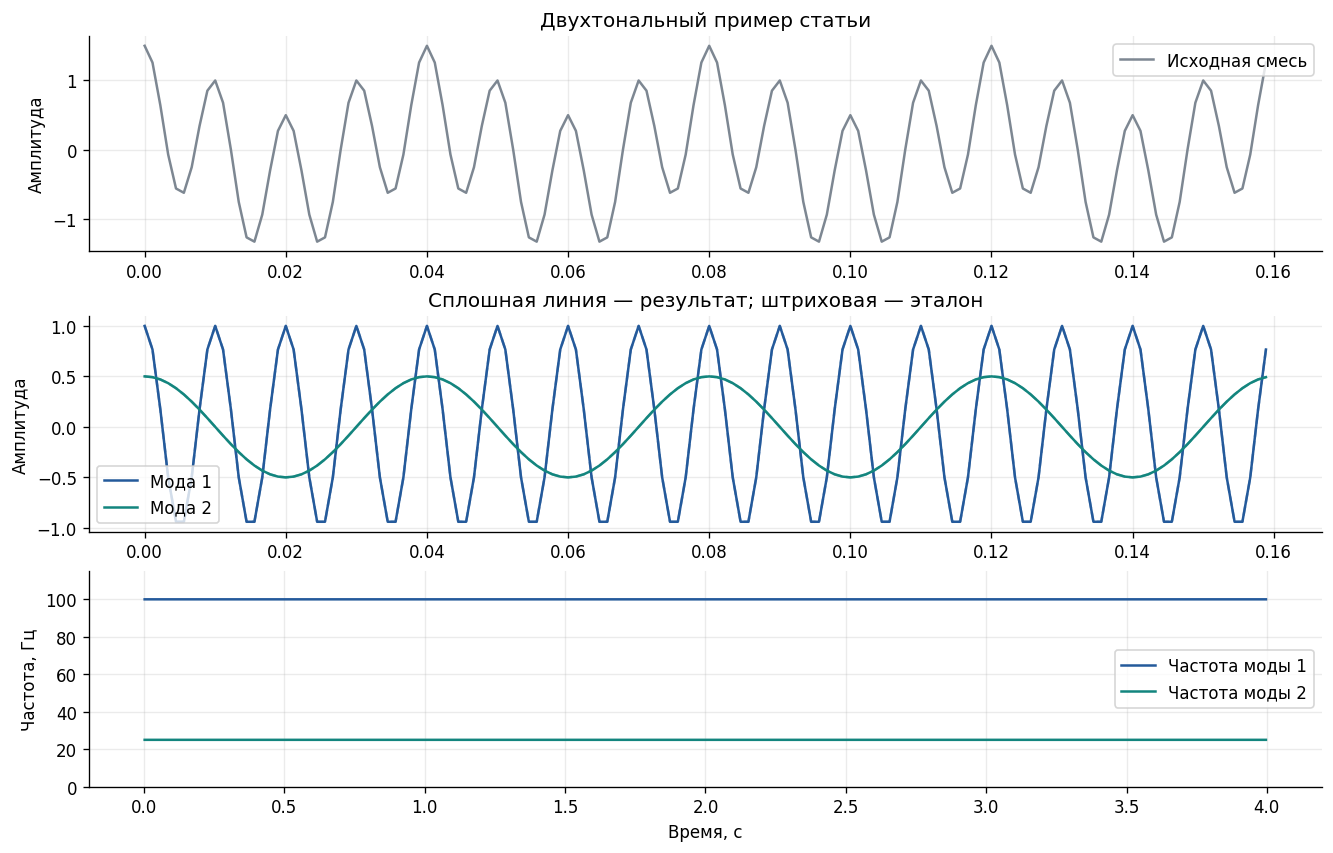

In [9]:
fs_article = 900.0
n_article = np.arange(3600)
t_article = n_article / fs_article
true_article = np.array([
    np.cos(2*np.pi*100*n_article/900),
    0.5*np.cos(2*np.pi*25*n_article/900),
])
x_article = true_article.sum(axis=0)
result_article = decompose_fixed(x_article, [9, 36], iterations=8, boundary="wrap")
features_article = [analytic_features(c, fs_article, trim=2) for c in result_article.modes]

article_err1 = relative_error(result_article.modes[0], true_article[0])
article_err2 = relative_error(result_article.modes[1], true_article[1])
article_fmae1 = float(np.nanmean(np.abs(features_article[0].frequency - 100)))
article_fmae2 = float(np.nanmean(np.abs(features_article[1].frequency - 25)))
article_residual = float(np.linalg.norm(result_article.residual)/np.linalg.norm(x_article))
article_reconstruction = relative_error(result_article.reconstruct(), x_article)

article_metrics = {
    "mode1_relative_L2": article_err1, "mode2_relative_L2": article_err2,
    "mode1_frequency_MAE_Hz": article_fmae1, "mode2_frequency_MAE_Hz": article_fmae2,
    "residual_relative_L2": article_residual, "reconstruction_relative_L2": article_reconstruction,
}
summary_metrics["article_two_tones"] = article_metrics
display(pd.DataFrame({
    "Величина": ["Ошибка моды 100 Гц", "Ошибка моды 25 Гц", "MAE частоты 100 Гц, Гц",
                 "MAE частоты 25 Гц, Гц", "Норма остатка / норма сигнала", "Ошибка восстановления"],
    "В статье": [7.60e-7, 1.52e-6, 3.38e-5, 2.07e-12, 1.16e-14, 0.0],
    "В этом запуске": list(article_metrics.values()),
}))

check("Статья: ошибка первой моды совпадает с опубликованным округлением",
      np.isclose(article_err1, 7.60e-7, rtol=0.005))
check("Статья: ошибка второй моды совпадает с опубликованным округлением",
      np.isclose(article_err2, 1.52e-6, rtol=0.005))
check("Статья: MAE частоты первой моды совпадает с округлением",
      np.isclose(article_fmae1, 3.38e-5, rtol=0.005))
check("Статья: частота второй моды точна до ошибок округления", article_fmae2 < 1e-9)
check("Статья: малый конечный остаток", article_residual < 1e-12)
check("Статья: восстановление с остатком", article_reconstruction < 1e-14)

theta_low = 2*np.pi*25/fs_article
b9_low = np.sin(9*theta_low/2)/(9*np.sin(theta_low/2))
leakage = (1 - b9_low**2)**8
check("Ошибка первой моды независимо объясняется проникновением второго тона",
      np.isclose(article_err1, 0.5*leakage, rtol=1e-6))
check("Ошибка второй моды независимо объясняется коэффициентом проникновения",
      np.isclose(article_err2, leakage, rtol=1e-6))

fig, ax = plt.subplots(3, 1, figsize=(11, 7), constrained_layout=True)
zoom = t_article < 0.16
ax[0].plot(t_article[zoom], x_article[zoom], color=GREY, label="Исходная смесь")
ax[0].set(ylabel="Амплитуда", title="Двухтональный пример статьи")
for j, color in enumerate([BLUE, TEAL]):
    ax[1].plot(t_article[zoom], result_article.modes[j, zoom], color=color, label=f"Мода {j+1}")
    ax[1].plot(t_article[zoom], true_article[j, zoom], "--", color=color, alpha=0.5)
    ax[2].plot(t_article, features_article[j].frequency, color=color, label=f"Частота моды {j+1}")
ax[0].legend(); ax[1].legend(); ax[2].legend()
ax[1].set(ylabel="Амплитуда", title="Сплошная линия — результат; штриховая — эталон")
ax[2].set(xlabel="Время, с", ylabel="Частота, Гц", ylim=(0, 115))
plt.show()

## 6. Пример 3: те же два тона, длины определяются по данным

Теперь передаём алгоритму только сигнал и частоту дискретизации.
Начальная длина каждой моды — медиана интервалов между соседними максимумами
и соседними минимумами текущего остатка. Полные периоды уменьшают ошибку
округления, возникающую при удвоении отдельно измеренного полупериода.

Истинные частоты используются только в проверках. Для этой чистой разделённой
смеси ожидаются длины 9 и 36; это не гарантия для произвольных смесей и шума.

In [10]:
auto_article = decompose_auto(x_article, fs_article, max_modes=2,
                              iterations=8, boundary="wrap")
check("Автоматический масштаб: два выделенных тона", len(auto_article.modes) == 2)
check("Автоматический масштаб: периоды 9 и 36 отсчётов", auto_article.lengths == [9, 36])
check("Автоматический масштаб: первая компонента", relative_error(auto_article.modes[0], true_article[0]) < 1e-5)
check("Автоматический масштаб: вторая компонента", relative_error(auto_article.modes[1], true_article[1]) < 1e-5)
check("Автоматический масштаб: сохранение суммы", relative_error(auto_article.reconstruct(), x_article) < 1e-14)
summary_metrics["automatic_lengths_two_tones"] = auto_article.lengths
display(pd.DataFrame({
    "Мода": [1, 2], "Выбранная L": auto_article.lengths,
    "Шаги": auto_article.iterations,
    "Относительная ошибка": [relative_error(auto_article.modes[j], true_article[j]) for j in range(2)],
}))

,Мода,Выбранная L,Шаги,Относительная ошибка
0,1,9,8,7.595675e-07
1,2,36,8,1.519135e-06


## 7. Пример 4: чирп-сигнал и постоянный тон из статьи

Та же иллюстративная модель:
$$x(t)=\cos[2\pi(20t+t^2)]+0.6\cos(2\pi5t),\quad0\leq t<10.$$
Её истинные частоты — $20+2t$ Гц и 5 Гц. Берём $f_s=400$ Гц.

Сравниваем четыре варианта:
1. фиксированное двойное усреднение с начальной длиной по экстремумам;
2. одинарный переменный вектор с нечётным $L[n]\approx f_s/\widehat f[n]$;
3. **выбор по данным:** пилот → сглаженная производная фазы → два уточнения RIF;
4. **эталонная проверка фильтра:** RIF с заранее известной истинной частотой.

Вариант 4 измеряет ошибку дискретизации при правильном масштабе. Он не является
проверкой автоматического выявления частот.

В RIF на равномерной фазовой сетке сохраняются элементарные веса $1/L$.
Используются линейная интерполяция и FIR-передискретизация во времени, без сплайнов.
Из-за интерполяции численная конструкция только приближает непрерывный оператор (23).
Первую и последнюю секунды исключаем из ошибок компонент/частот; восстановление
с остатком проверяем на **всей** записи.

,Метод,Ошибка компоненты на 1–9 с
0,Фиксированная L по данным,0.245299
1,"Переменная L[n], одинарное среднее",0.340750
2,RIF с фазой по данным,0.001593
3,RIF с истинной фазой (контроль),0.001638
4,Вторая мода 5 Гц,0.002624


,phase_grid_points,length_in_phase,cycle_window,oversample,mean_ratio,valid_fraction,Уточнение
0,19195,64,0.999985,4,0.001459,0.8,1
1,19194,64,1.000008,4,0.001443,0.8,2


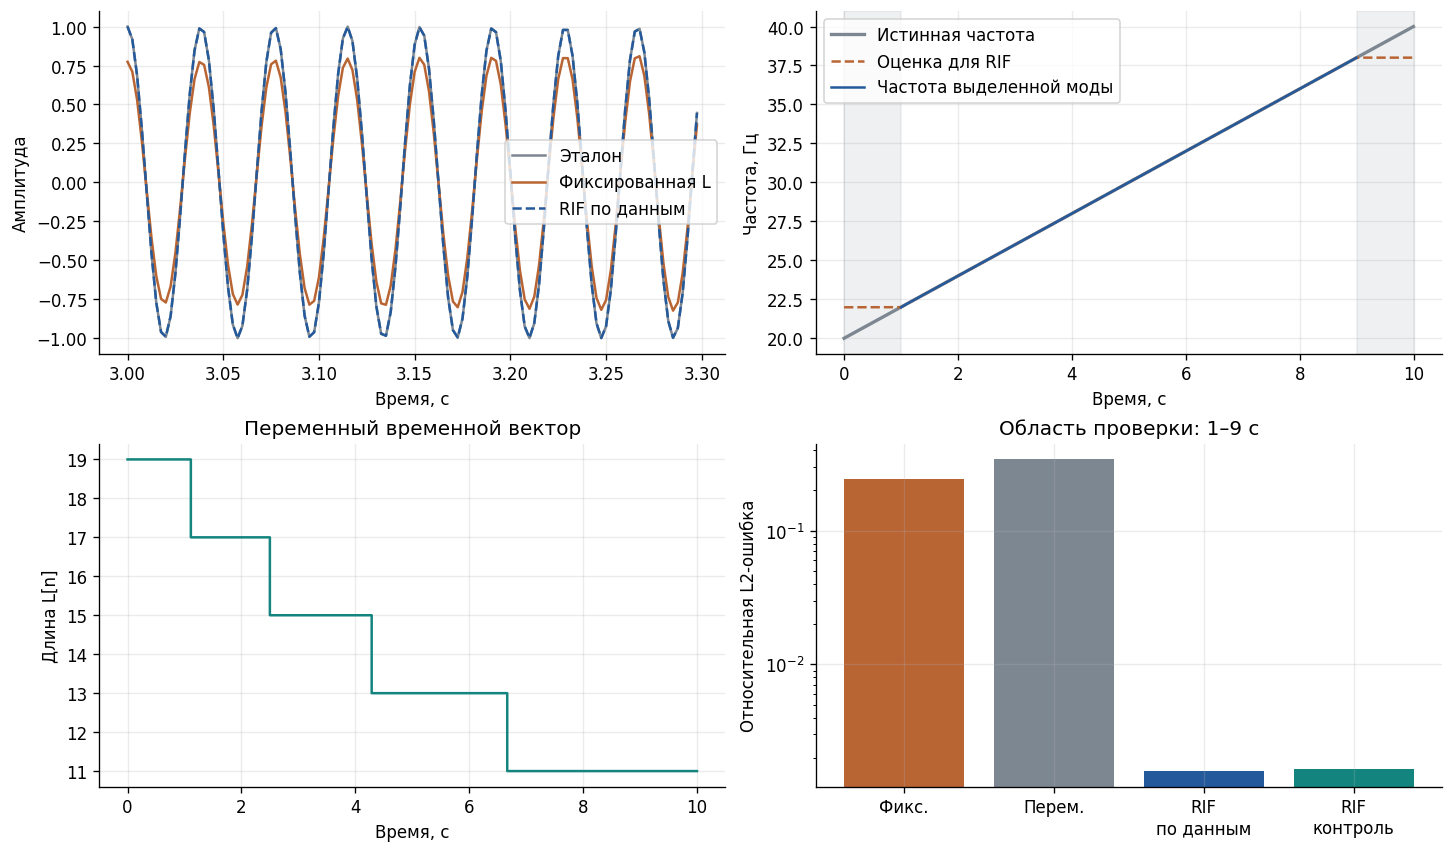

In [11]:
fs_chirp = 400.0
t_chirp = np.arange(4000)/fs_chirp
true_chirp = np.cos(2*np.pi*(20*t_chirp + t_chirp**2))
true_low = 0.6*np.cos(2*np.pi*5*t_chirp)
true_chirp_frequency = 20 + 2*t_chirp
x_chirp = true_chirp + true_low
central = (t_chirp >= 1) & (t_chirp < 9)

initial_length = estimate_length_extrema(x_chirp)
pilot_chirp = sift_fixed(x_chirp, initial_length, boundary="reflect", iterations=8).mode

# Только x и fs: истинная частота этой функции не передаётся.
guided_chirp, frequency_guide, guide_info = hilbert_guided_extract(
    x_chirp, fs_chirp, iterations=8, refinements=2, trim_seconds=1,
    smooth_window=51, samples_per_cycle=64, oversample=4,
)
# Истинная частота передаётся только в отдельный контрольный опыт.
oracle_chirp, oracle_info = phase_resampled_sift(
    x_chirp, fs_chirp, true_chirp_frequency, iterations=8,
    samples_per_cycle=64, oversample=4,
)
odd_lengths = (2*np.rint((fs_chirp/frequency_guide - 1)/2) + 1).astype(int)
variable_chirp = sift_variable(x_chirp, odd_lengths, iterations=8,
                               boundary="reflect", growth_limit=5).mode

low_result = decompose_auto(x_chirp-guided_chirp, fs_chirp, max_modes=1,
                            iterations=8, boundary="reflect")
guided_low = low_result.modes[0]
chirp_residual = low_result.residual
chirp_features = analytic_features(guided_chirp, fs_chirp, boundary="reflect",
                                   trim=400, smooth_window=51)
chirp_error = relative_error(guided_chirp, true_chirp, central)
pilot_error = relative_error(pilot_chirp, true_chirp, central)
oracle_error = relative_error(oracle_chirp, true_chirp, central)
chirp_fmae = float(np.nanmean(np.abs(chirp_features.frequency - true_chirp_frequency)))
low_error = relative_error(guided_low, true_low, central)
chirp_reconstruction = relative_error(guided_chirp + guided_low + chirp_residual, x_chirp)

chirp_metrics = {
    "initial_length": initial_length,
    "fixed_component_error": pilot_error,
    "variable_component_error": relative_error(variable_chirp, true_chirp, central),
    "guided_component_error": chirp_error, "oracle_component_error": oracle_error,
    "guided_frequency_MAE_Hz": chirp_fmae, "low_tone_error": low_error,
    "reconstruction_relative_L2": chirp_reconstruction,
    "guide_frequency_MAE_Hz": float(np.mean(abs(frequency_guide[central]-true_chirp_frequency[central]))),
}
summary_metrics["chirp"] = chirp_metrics
display(pd.DataFrame({
    "Метод": ["Фиксированная L по данным", "Переменная L[n], одинарное среднее",
              "RIF с фазой по данным", "RIF с истинной фазой (контроль)", "Вторая мода 5 Гц"],
    "Ошибка компоненты на 1–9 с": [pilot_error, chirp_metrics["variable_component_error"],
                                    chirp_error, oracle_error, low_error],
}))
display(pd.DataFrame(guide_info["history"]).assign(Уточнение=[1, 2]))
check("Чирп: RIF по данным восстанавливает компоненту с ошибкой <2%", chirp_error < 0.02)
check("Чирп: RIF улучшает фиксированный масштаб в этом опыте", chirp_error < 0.1*pilot_error)
check("Чирп: средняя ошибка мгновенной частоты <0.1 Гц", chirp_fmae < 0.1)
check("Чирп: контроль с истинной частотой имеет малую ошибку", oracle_error < 0.02)
check("Чирп: второй тон восстановлен с ошибкой <2%", low_error < 0.02)
check("Чирп: восстановление на всей записи с остатком", chirp_reconstruction < 1e-14)
check("Фазовая сетка: окно равно примерно одному периоду",
      abs(oracle_info["cycle_window"]-1) < 0.002)

fig, ax = plt.subplots(2, 2, figsize=(12, 7), constrained_layout=True)
zoom = (t_chirp >= 3) & (t_chirp < 3.3)
ax[0, 0].plot(t_chirp[zoom], true_chirp[zoom], color=GREY, label="Эталон")
ax[0, 0].plot(t_chirp[zoom], pilot_chirp[zoom], color=ORANGE, label="Фиксированная L")
ax[0, 0].plot(t_chirp[zoom], guided_chirp[zoom], "--", color=BLUE, label="RIF по данным")
ax[0, 0].set(xlabel="Время, с", ylabel="Амплитуда"); ax[0, 0].legend()
ax[0, 1].plot(t_chirp, true_chirp_frequency, color=GREY, lw=2, label="Истинная частота")
ax[0, 1].plot(t_chirp, frequency_guide, "--", color=ORANGE, label="Оценка для RIF")
ax[0, 1].plot(t_chirp, chirp_features.frequency, color=BLUE, label="Частота выделенной моды")
for start, stop in [(0, 1), (9, 10)]:
    ax[0, 1].axvspan(start, stop, color=GREY, alpha=0.12)
ax[0, 1].set(xlabel="Время, с", ylabel="Частота, Гц"); ax[0, 1].legend()
ax[1, 0].step(t_chirp, odd_lengths, color=TEAL, where="mid")
ax[1, 0].set(xlabel="Время, с", ylabel="Длина L[n]", title="Переменный временной вектор")
errors = [pilot_error, chirp_metrics["variable_component_error"], chirp_error, oracle_error]
ax[1, 1].bar(["Фикс.", "Перем.", "RIF\nпо данным", "RIF\nконтроль"], errors,
              color=[ORANGE, GREY, BLUE, TEAL])
ax[1, 1].set(yscale="log", ylabel="Относительная L2-ошибка", title="Область проверки: 1–9 с")
plt.show()

## 8. Пример 5: амплитудная модуляция, квадратура и шум

Сначала задаём чистую компоненту
$$c(t)=[1+0.3\sin(2\pi0.5t)]\cos(2\pi100t).$$

Для проверки квадратуры огибающая известна и положительна. Сравниваем
прямую квадратуру (18) с нормализованным преобразованием Гильберта.
Это контроль частотного считывания, а не демонстрация автоматического
восстановления неизвестной огибающей.

Затем добавляем тон 25 Гц, постоянный остаток 0.2 и гауссовский шум
$\sigma=0.03$. Фиксированные длины 9 и 36 заданы как в предыдущем контроле.
Сравниваем обычную производную фазы и производную Savitzky–Golay,
окно 51 отсчёт. Шум в сохраняемых полосах остаётся в модах:
фильтрация IF сама по себе не является универсальным подавлением шума.

,seed,mode_error,raw_MAE_Hz,smoothed_MAE_Hz,reconstruction_error
0,20261009,0.034317,2.312276,0.083687,6.317742e-17
1,20261010,0.034165,2.329177,0.082379,6.163598e-17
2,20261011,0.034381,2.337691,0.083282,6.250556e-17


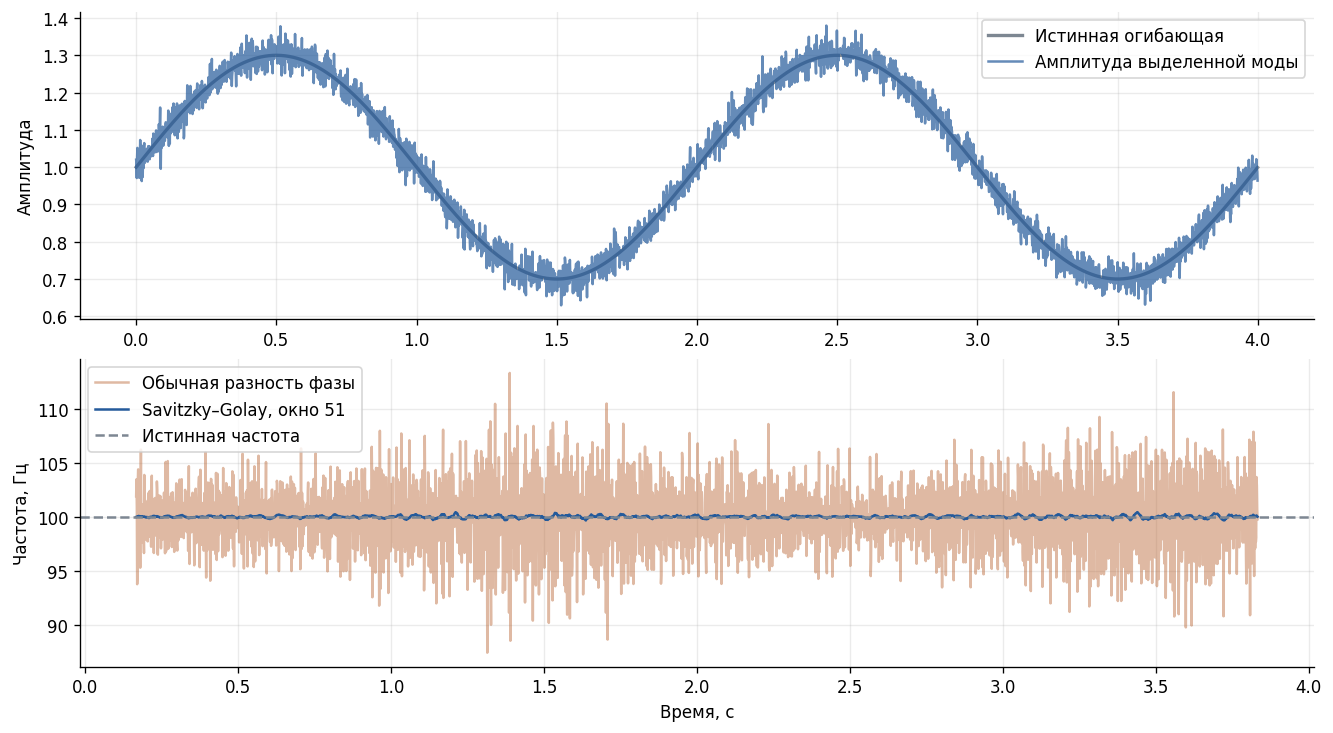

In [12]:
fs_am = 900.0
t_am = np.arange(3600)/fs_am
envelope_am = 1 + 0.3*np.sin(2*np.pi*0.5*t_am)
clean_am = envelope_am*np.cos(2*np.pi*100*t_am)
quadrature_am = quadrature_features(clean_am, fs_am, envelope_am)
normalized_am = analytic_features(clean_am/envelope_am, fs_am, trim=2)

q_mae = float(np.nanmean(abs(quadrature_am.frequency-100)))
normalized_mae = float(np.nanmean(abs(normalized_am.frequency-100)))
check("Прямая квадратура: известная AM-огибающая", q_mae < 1e-8)
check("Нормализованный Гильберт: известная AM-огибающая", normalized_mae < 1e-8)
check("Квадратура сохраняет вещественную компоненту",
      relative_error(quadrature_am.z.real, clean_am) < 1e-14)

noise_results = []
for seed in [SEED, SEED+1, SEED+2]:
    noisy_x = clean_am + 0.5*np.cos(2*np.pi*25*t_am) + 0.2
    noisy_x = noisy_x + np.random.default_rng(seed).normal(0, 0.03, len(t_am))
    noisy_result = decompose_fixed(noisy_x, [9, 36], iterations=8)
    raw_features = analytic_features(noisy_result.modes[0], fs_am, trim=150)
    smooth_features = analytic_features(noisy_result.modes[0], fs_am, trim=150, smooth_window=51)
    row = {
        "seed": seed, "mode_error": relative_error(noisy_result.modes[0], clean_am),
        "raw_MAE_Hz": float(np.nanmean(abs(raw_features.frequency-100))),
        "smoothed_MAE_Hz": float(np.nanmean(abs(smooth_features.frequency-100))),
        "reconstruction_error": relative_error(noisy_result.reconstruct(), noisy_x),
    }
    noise_results.append(row)
    check(f"Шум: восстановление с остатком, seed={seed}", row["reconstruction_error"] < 1e-14)
    if seed == SEED:
        demo_noisy_result, demo_raw, demo_smooth = noisy_result, raw_features, smooth_features
noise_table = pd.DataFrame(noise_results)
display(noise_table)
check("Шум: сглаживание уменьшает среднюю MAE в трёх контрольных реализациях",
      noise_table["smoothed_MAE_Hz"].mean() < noise_table["raw_MAE_Hz"].mean())
summary_metrics["noise"] = noise_results
summary_metrics["quadrature_AM_MAE_Hz"] = q_mae

fig, ax = plt.subplots(2, 1, figsize=(11, 6), constrained_layout=True)
ax[0].plot(t_am, envelope_am, color=GREY, lw=2, label="Истинная огибающая")
ax[0].plot(t_am, demo_smooth.amplitude, color=BLUE, alpha=0.7, label="Амплитуда выделенной моды")
ax[0].set(ylabel="Амплитуда"); ax[0].legend()
ax[1].plot(t_am, demo_raw.frequency, color=ORANGE, alpha=0.45, label="Обычная разность фазы")
ax[1].plot(t_am, demo_smooth.frequency, color=BLUE, label="Savitzky–Golay, окно 51")
ax[1].axhline(100, color=GREY, ls="--", label="Истинная частота")
ax[1].set(xlabel="Время, с", ylabel="Частота, Гц")
ax[1].legend()
plt.show()

## 9. Пример 6: нулевая амплитуда и смешанный аналитический сигнал

У $[0.5+0.5\cos(2\pi t)]\cos(2\pi30t)$ огибающая обращается в ноль.
Частота в этих точках не определена. Порог амплитуды 5% и запас по ширине
дифференцирования исключают недостоверные точки; они остаются *NaN*,
а не превращаются в нулевую частоту.

Для смеси $\cos(2\pi30t)+0.7\cos(2\pi50t)$ единственная аналитическая фаза
не даёт две частоты. Её мгновенная частота может быть отрицательной даже при
положительных частотах обоих исходных тонов. Спектральная производная
применяется к этому периодическому примеру для точного частотного считывания.

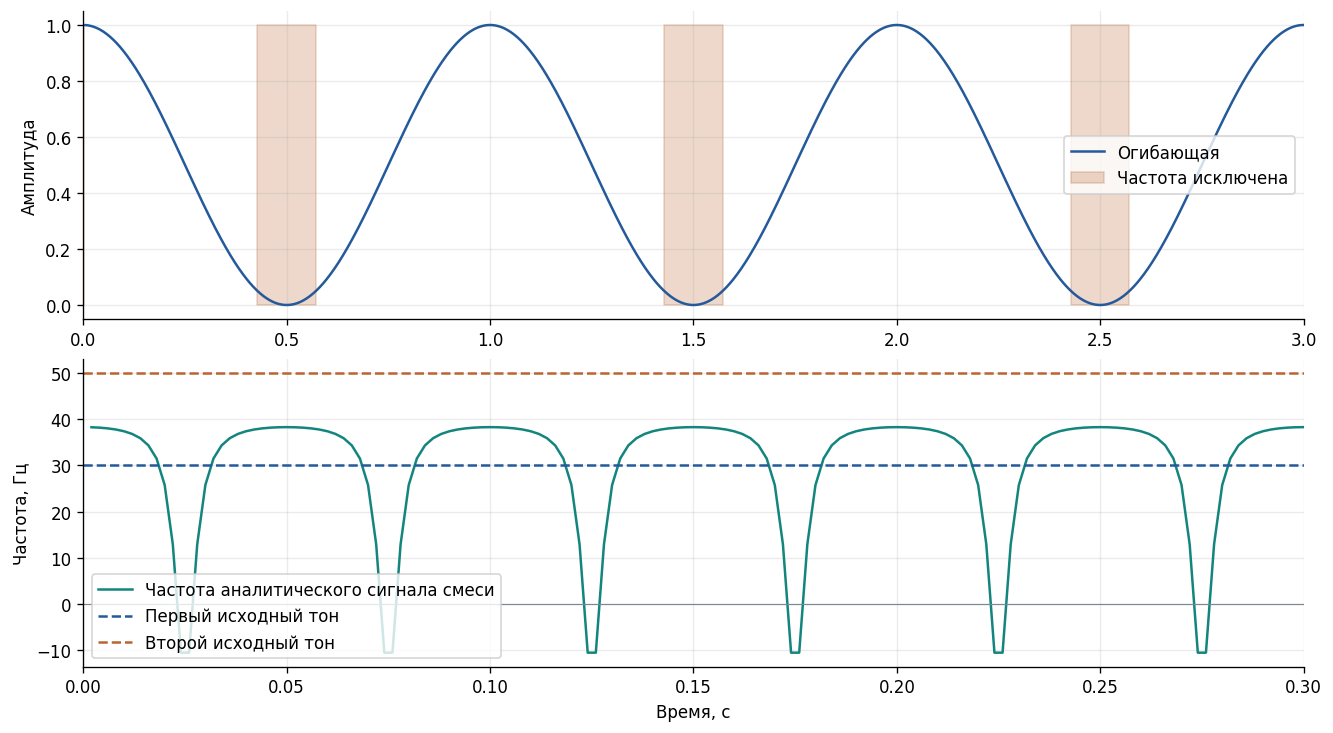

In [13]:
fs_singular = 500.0
t_singular = np.arange(2500)/fs_singular
zero_envelope = 0.5 + 0.5*np.cos(2*np.pi*t_singular)
zero_signal = zero_envelope*np.cos(2*np.pi*30*t_singular)
zero_features = analytic_features(zero_signal, fs_singular, amplitude_floor=0.05, trim=2)
check("Нули амплитуды исключаются из частотной оценки", (~zero_features.valid).mean() > 0.1)
check("В исключённых точках частота NaN", np.all(np.isnan(zero_features.frequency[~zero_features.valid])))
check("В допустимых точках нулевой AM-пример имеет частоту 30 Гц",
      np.nanmean(abs(zero_features.frequency-30)) < 1e-8)

mixture = np.cos(2*np.pi*30*t_singular) + 0.7*np.cos(2*np.pi*50*t_singular)
mixture_features = analytic_features(mixture, fs_singular, derivative="spectral")
check("Частота аналитического сигнала смеси может быть отрицательной",
      np.nanmin(mixture_features.frequency) < -10)

constant_result = decompose_auto(np.full(100, 2.0), 100)
zero_result = decompose_auto(np.zeros(100), 100)
check("Постоянный сигнал остаётся остатком", len(constant_result.modes) == 0 and
      np.allclose(constant_result.residual, 2))
check("Нулевой сигнал не порождает фиктивных мод", len(zero_result.modes) == 0 and
      zero_result.reason == "zero_signal")
zero_analytic = analytic_features(np.zeros(100), 100)
check("Нулевой аналитический сигнал не имеет частоты", np.isnan(zero_analytic.frequency).all())

must_raise("Вход NaN отклоняется", lambda: sift_fixed([1, np.nan, 0], 3))
must_raise("Комплексный вход разложения отклоняется", lambda: decompose_auto(np.ones(10)*1j, 100))
must_raise("Чётная L одинарного центрированного фильтра отклоняется",
           lambda: averaging_kernel(4, double=False))
must_raise("Неположительная fs отклоняется", lambda: analytic_features(np.arange(10), 0))
must_raise("Неположительный фазовый профиль отклоняется",
           lambda: phase_resampled_sift(np.ones(20), 100, np.zeros(20)))
must_raise("Чётные переменные длины отклоняются",
           lambda: moving_average_variable(np.ones(20), np.full(20, 4)))
must_raise("Неверная огибающая квадратуры отклоняется",
           lambda: quadrature_features(np.ones(20), 100, 0.5))
must_raise("FFT с отражёнными границами отклоняется",
           lambda: sift_fixed(np.ones(20), 3, boundary="reflect", backend="fft"))

summary_metrics["singular_valid_fraction"] = float(zero_features.valid.mean())
summary_metrics["mixture_minimum_frequency_Hz"] = float(np.nanmin(mixture_features.frequency))
fig, ax = plt.subplots(2, 1, figsize=(11, 6), constrained_layout=True)
ax[0].plot(t_singular, zero_envelope, color=BLUE, label="Огибающая")
ax[0].fill_between(t_singular, 0, 1, where=~zero_features.valid,
                   color=ORANGE, alpha=0.25, label="Частота исключена")
ax[0].set(ylabel="Амплитуда", xlim=(0, 3)); ax[0].legend()
ax[1].plot(t_singular, mixture_features.frequency, color=TEAL, label="Частота аналитического сигнала смеси")
ax[1].axhline(30, color=BLUE, ls="--", label="Первый исходный тон")
ax[1].axhline(50, color=ORANGE, ls="--", label="Второй исходный тон")
ax[1].axhline(0, color=GREY, lw=0.7)
ax[1].set(xlabel="Время, с", ylabel="Частота, Гц", xlim=(0, 0.3)); ax[1].legend()
plt.show()

## 10. Синтез по мгновенной частоте и локальный аналог ДПФ

### 10.1 Сохранение начальной фазы

В дискретном точном синтезе используем частоту, среднюю на интервале:
$$f[n+1/2]=\frac{\phi[n+1]-\phi[n]}{2\pi\Delta t},\quad
\phi[n]=\phi[0]+2\pi\Delta t\sum_{k<n}f[k+1/2].$$
Такой интеграл точно восстанавливает сохранённую дискретную фазу.
Интегрирование точечных оценок из *np.gradient* было бы численной квадратурой,
с дополнительной ошибкой. При нулях амплитуды формула применяется на отдельных
допустимых интервалах.

### 10.2 Плотность с сохранением фазы

Для равномерных частотных ячеек шириной $\Delta f$ вклад в плотность равен
$z_j[n]/\Delta f$. Проверяем
$$x[n]=r_J[n]+\operatorname{Re}\{\Delta f\sum_k C[k,n]+\text{unassigned}[n]\}.$$
Неопределённые и выходящие за сетку вклады сохраняются отдельно, поэтому
маскирование частоты не теряет часть исходного сигнала.
Амплитудная карта $H_A$ служит визуализации и сама по себе фазу не сохраняет.

### 10.3 Локальные коэффициенты

Формула (28) требует матрицы Грама. Проверяем её точное сведение к нормированному
ДПФ для полного словаря и корректную проекцию на два близких неортогональных
осциллятора. Здесь словарь уже известен; этот шаг не выявляет его автоматически.

,Коэффициент,Истинный,Без поправки,С матрицей Грама
0,1,1.0+0.0j,0.879004+0.374386j,1.0-0.0j
1,2,0.0+0.4j,0.935966+0.097511j,-0.0+0.4j


Число обусловленности матрицы Грама: 121.1899935556326


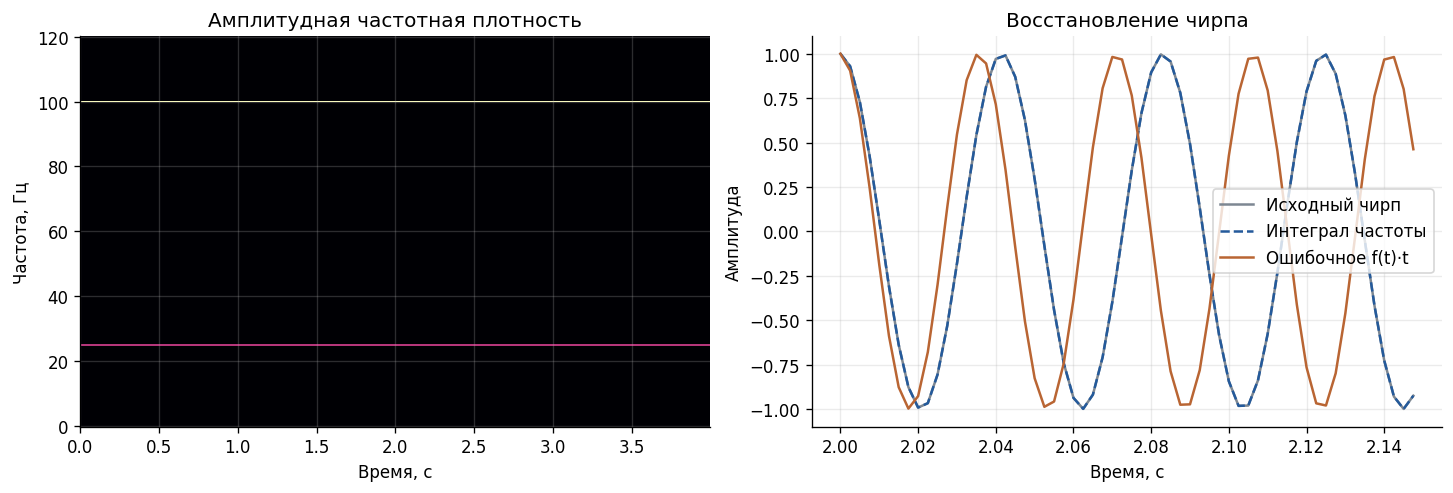

In [14]:
article_amplitudes = np.array([f.amplitude for f in features_article])
article_phases = np.array([f.phase for f in features_article])
interval_frequencies = np.diff(article_phases, axis=1)*fs_article/(2*np.pi)
synthesized_article = synthesize_from_intervals(
    article_amplitudes, article_phases[:, 0], interval_frequencies,
    result_article.residual, fs_article,
)
synthesis_error = relative_error(synthesized_article, x_article)
check("Интеграл интервальной частоты сохраняет дискретную фазу", synthesis_error < 1e-10)

frequency_grid = np.arange(0, 120.5, 0.5)
complex_density, unassigned = frequency_density(features_article, frequency_grid, keep_phase=True)
amplitude_density, _ = frequency_density(features_article, frequency_grid, keep_phase=False)
df = frequency_grid[1]-frequency_grid[0]
density_synthesis = result_article.residual + (df*complex_density.sum(axis=0) + unassigned).real
density_error = relative_error(density_synthesis, x_article)
check("Частотная интегральная плотность с фазой сохраняет сигнал", density_error < 1e-12)
check("Неопределённые краевые вклады не потеряны", np.linalg.norm(unassigned) > 0)

# Полный словарь: нормированные коэффициенты ДПФ.
N_dft = 16
u_dft = np.exp(2j*np.pi*np.outer(np.arange(N_dft), np.arange(N_dft))/N_dft)
z_dft = np.random.default_rng(SEED+7).normal(size=N_dft) + 1j*np.random.default_rng(SEED+8).normal(size=N_dft)
coef_dft, gram_dft, condition_dft = oscillator_projection(z_dft, u_dft)
check("Матрица Грама полного словаря Фурье равна I",
      np.allclose(gram_dft, np.eye(N_dft), atol=2e-14))
check("Локальная проекция для полного словаря = DFT/N",
      np.allclose(coef_dft, np.fft.fft(z_dft)/N_dft, atol=2e-14))

# Известный неортогональный словарь: отдельная проверка формулы (28).
t_local = np.arange(200)/400
u_local = np.exp(2j*np.pi*np.array([30, 30.2])[:, None]*t_local)
true_coefficients = np.array([1.0, 0.4j])
z_local = true_coefficients @ u_local
coef_local, gram_local, condition_local = oscillator_projection(z_local, u_local)
naive_projection = u_local.conj() @ z_local / len(z_local)
check("Матрица Грама корректирует неортогональную проекцию",
      np.allclose(coef_local, true_coefficients, atol=2e-12))
check("Одни скалярные произведения не являются верными коэффициентами",
      np.linalg.norm(naive_projection-true_coefficients) > 0.1)
display(pd.DataFrame({
    "Коэффициент": [1, 2], "Истинный": true_coefficients,
    "Без поправки": naive_projection, "С матрицей Грама": coef_local,
}))
print("Число обусловленности матрицы Грама:", condition_local)
summary_metrics["interval_frequency_synthesis_error"] = synthesis_error
summary_metrics["frequency_density_synthesis_error"] = density_error
summary_metrics["nonorthogonal_gram_condition"] = condition_local

# Для чирпа интеграл истинной частоты точен, потому что f(t) линейна.
t_mid = (t_chirp[:-1]+t_chirp[1:])/2
correct_chirp = synthesize_from_intervals(
    np.ones((1, len(t_chirp))), np.array([0.0]), (20+2*t_mid)[None, :],
    np.zeros(len(t_chirp)), fs_chirp,
)
incorrect_chirp = np.cos(2*np.pi*true_chirp_frequency*t_chirp)
check("Чирп: частоту нужно интегрировать, а не умножать на t",
      relative_error(correct_chirp, true_chirp) < 1e-10 and
      relative_error(incorrect_chirp, true_chirp) > 0.5)

fig, ax = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
ax[0].pcolormesh(t_article, frequency_grid, amplitude_density, shading="auto", cmap="magma")
ax[0].set(xlabel="Время, с", ylabel="Частота, Гц", title="Амплитудная частотная плотность")
zoom = (t_chirp >= 2) & (t_chirp < 2.15)
ax[1].plot(t_chirp[zoom], true_chirp[zoom], color=GREY, label="Исходный чирп")
ax[1].plot(t_chirp[zoom], correct_chirp[zoom], "--", color=BLUE, label="Интеграл частоты")
ax[1].plot(t_chirp[zoom], incorrect_chirp[zoom], color=ORANGE, label="Ошибочное f(t)·t")
ax[1].set(xlabel="Время, с", ylabel="Амплитуда", title="Восстановление чирпа")
ax[1].legend()
plt.show()

## 11. Итог проверки

Пороговые проверки заданы для конкретных тестовых моделей. Они охватывают
центрирование, нечётную/чётную базовую длину, обе вычислительные формы,
интегральное тождество, независимый прогноз проникновения, оценивание частот,
передискретизацию, синтез и обработку недопустимых данных.

Остановка после конечного числа шагов является частью метода. Моды могут
смешиваться; сохранение суммы не означает идентификацию физических причин.
Ошибки чирпа оценены на 1–9 с. Шум проверен для трёх указанных seed.
В пересекающихся или плохо разделённых компонентах надёжный фазовый профиль
не гарантирован. Начальная оценка по экстремумам может ошибаться при шуме.

Для собственных данных укажите настоящую частоту дискретизации:
```python
# x — одномерный вещественный массив без NaN; fs — частота в Гц.
result = decompose_auto(x, fs, max_modes=5, iterations=8, boundary="reflect")
features = [
    analytic_features(c, fs, boundary="reflect",
                      trim=int(fs), smooth_window=51)
    for c in result.modes
]
restored = result.reconstruct()
# Частота: features[j].frequency; осциллятор: features[j].oscillator.
# Для записи короче 2 секунд уменьшите trim и smooth_window.
# Для адаптивного первого компонента:
c1, f_guide, diagnostics = hilbert_guided_extract(x, fs)
rest = x - c1
```

Отдельный модуль *kernel_emd.py* содержит тот же код; его можно импортировать
в другом проекте. Метрики этого запуска доступны в *validation_results.json*.

In [15]:
check("Все накопленные проверки пройдены", all(row["Пройдена"] for row in checks))
print(f"Пройдено проверок: {len(checks)}")
display(pd.DataFrame(checks))
display(pd.DataFrame({
    "Основной результат": [
        "Статья: ошибка моды 100 Гц", "Статья: ошибка моды 25 Гц",
        "Чирп: ошибка компоненты по данным на 1–9 с", "Чирп: MAE частоты, Гц",
        "Восстановление статьи с остатком", "Синтез по интервальной частоте",
    ],
    "Значение": [article_err1, article_err2, chirp_error, chirp_fmae,
                 article_reconstruction, synthesis_error],
}))

Пройдено проверок: 94


,Проверка,Пройдена,Комментарий
0,L=3: коэффициент усиления совпадает с (4/3)^20,True,
1,Двойное усреднение: периодическое просеивание ...,True,
2,L=3: тон в нуле фильтра сохраняется,True,
3,L=5: тон в нуле фильтра сохраняется,True,
4,"Дискретный интеграл: N=127, L=3",True,
...,...,...,...
89,Локальная проекция для полного словаря = DFT/N,True,
90,Матрица Грама корректирует неортогональную про...,True,
91,Одни скалярные произведения не являются верным...,True,
92,"Чирп: частоту нужно интегрировать, а не умножа...",True,


,Основной результат,Значение
0,Статья: ошибка моды 100 Гц,7.595675e-07
1,Статья: ошибка моды 25 Гц,1.519135e-06
2,Чирп: ошибка компоненты по данным на 1–9 с,1.593144e-03
3,"Чирп: MAE частоты, Гц",7.192319e-04
4,Восстановление статьи с остатком,4.632955e-17
5,Синтез по интервальной частоте,1.285722e-11


## Источники и воспроизводимость

- Исходная статья: *emd_instantaneous_frequency_article_ru.md*, разделы 3–9.
- Lin, Wang, Zhou (2009), [Iterative filtering](https://doi.org/10.1142/S179353690900028X).
- Cicone, Zhou (2021), [FFT implementations of IF](https://doi.org/10.1007/s00211-020-01165-5).
- Barbarino, Cicone (2024), [Resampled Iterative Filtering](https://doi.org/10.1007/s00211-024-01394-y).
- [SciPy: аналитический сигнал hilbert](https://docs.scipy.org/doc/scipy/reference/generated/scipy.signal.hilbert.html).
- [SciPy: convolve1d и граничные условия](https://docs.scipy.org/doc/scipy/reference/generated/scipy.ndimage.convolve1d.html).
- [SciPy: FIR-передискретизация resample_poly](https://docs.scipy.org/doc/scipy/reference/generated/scipy.signal.resample_poly.html).
- [NumPy: rfft](https://numpy.org/doc/stable/reference/generated/numpy.fft.rfft.html).

При подготовке все Python-ячейки исполнены последовательно в одном пространстве
имён CPython; текст, таблицы и графики сохранены в стандартной структуре ipynb 4.5.
Функции не требуют состояния внешнего проекта и не читают внешние файлы.
В Jupyter для полного повторения используйте **Restart Kernel and Run All Cells**.